# Semantic Segmentation  Of Microplastics

In [1]:
import importlib.util
import subprocess
import sys

import csv
import random
import time
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from PIL import Image
from scipy import ndimage
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader

SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(4)

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

set_seed(SEED)

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

generator = torch.Generator()
generator.manual_seed(SEED)

print("PyTorch:", torch.__version__, "| устройство:", DEVICE)


PyTorch: 2.14.1+cu130 | устройство: cuda


## I. Dataset Exploration

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import shutil
from pathlib import Path
import time

SOURCE = Path('/content/drive/MyDrive/semantic-segmentation-of-microplastics-data')
DEST = Path('/content/microplastics-data')

shutil.copytree(SOURCE, DEST, dirs_exist_ok=True)

PosixPath('/content/microplastics-data')

In [4]:
DATA_DIR = Path('microplastics-data')

train = DATA_DIR / 'train'
val = DATA_DIR / 'val'
test = DATA_DIR / 'test'

print(f'train: {len(list((train / 'images').glob('*.jpg')))}')
print(f'val: {len(list((val / 'images').glob('*.jpg')))}')
print(f'test: {len(list((test / 'images').glob('*.jpg')))}')

train: 1391
val: 351
test: 755


In [5]:
train_image = Image.open(next((train / 'images').glob('*.jpg')))
print(f'image size: {train_image.size}')
print(f'image mode: {train_image.mode}')

image size: (384, 384)
image mode: RGB


In [6]:
train_mask = np.array(Image.open(next((train / 'masks').glob('*.png'))))
print(f'mask size: {train_mask.shape}')
print(f'mask labels: {np.unique(train_mask)}')

mask size: (384, 384)
mask labels: [0 1]


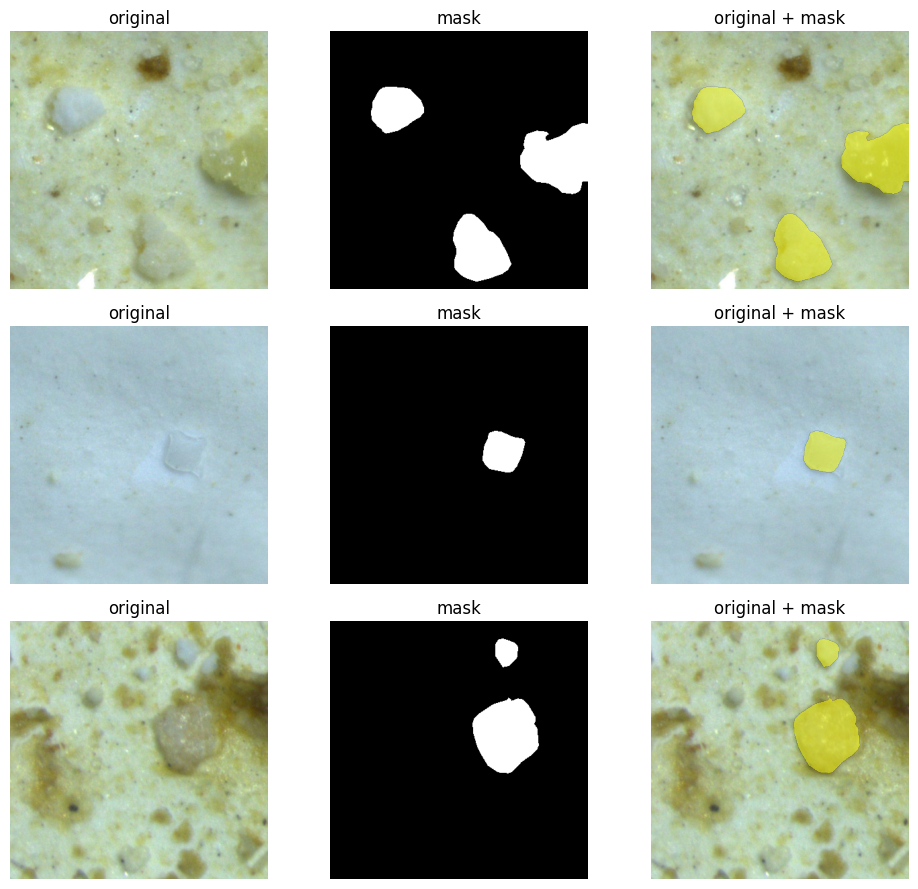

In [7]:
def load_image(path):
    with Image.open(path) as source:
        image = np.asarray(source.convert('RGB'), dtype=np.float32)
    return image / 255.

def read_pair(name, split='train'):
    image = load_image(DATA_DIR / split / 'images' / f'{name}.jpg')
    with Image.open(DATA_DIR / split / 'masks' / f'{name}.png') as source:
        mask = (np.asarray(source, dtype=np.uint8))
    return image, mask

def show_examples(names, split='train'):
    fig, axes = plt.subplots(len(names), 3, figsize=(10, 3 * len(names)), squeeze=False)
    for row, name in zip(axes, names):
        image, mask = read_pair(name, split)
        row[0].imshow(image)
        row[1].imshow(mask == 1, cmap='gray')
        row[2].imshow(image)
        row[2].imshow(np.ma.masked_where(mask != 1, mask), cmap='autumn', alpha=.5, vmin=0, vmax=1)
        for ax, title in zip(row, ['original', 'mask', 'original + mask']):
            ax.set_title(title); ax.axis('off')
    plt.tight_layout()
    plt.show()

train_names = sorted(p.stem for p in (train / 'images').glob('*.jpg'))
show_examples([train_names[i] for i in [20, 40, 60]])


In [8]:
def get_statistics(split='train'):
    mask_paths = sorted((DATA_DIR / split / 'masks').glob('*.png'))
    fractions = []

    for path in mask_paths:
        with Image.open(path) as source:
            mask = np.asarray(source)
        valid = mask != 255
        fraction = (mask[valid] == 1).mean() if valid.any() else np.nan
        fractions.append(fraction)

    return np.array(fractions)

train_fractions = get_statistics('train')
val_fractions = get_statistics('val')

print(f'train mean: {np.nanmean(train_fractions):.2%}')
print(f'train median: {np.nanmedian(train_fractions):.2%}')
print(f'train min: {np.nanmin(train_fractions):.2%}')
print(f'train max: {np.nanmax(train_fractions):.2%}')

print(f'\nval mean: {np.nanmean(val_fractions):.2%}')
print(f'val median: {np.nanmedian(val_fractions):.2%}')
print(f'val min: {np.nanmin(val_fractions):.2%}')
print(f'val max: {np.nanmax(val_fractions):.2%}')

train mean: 4.87%
train median: 2.57%
train min: 0.00%
train max: 83.52%

val mean: 5.49%
val median: 3.04%
val min: 0.00%
val max: 80.19%


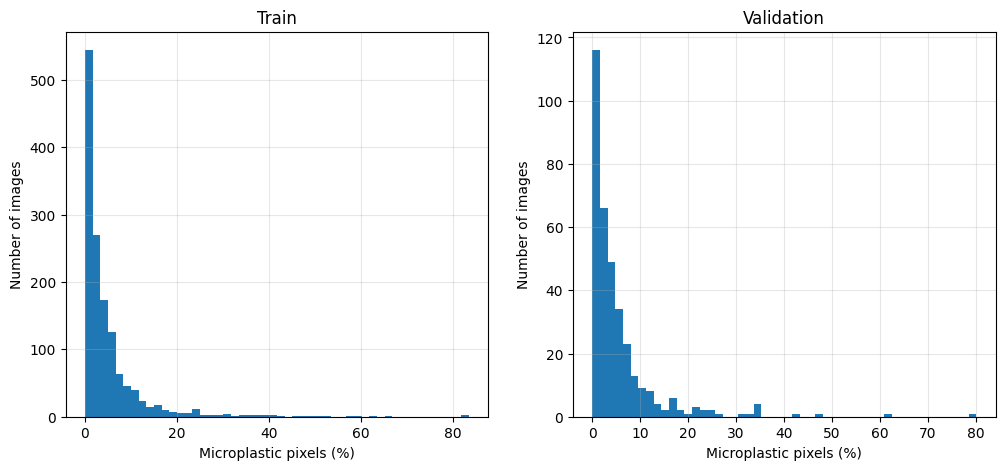

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), squeeze=False)

axes[0, 0].hist(train_fractions * 100, bins=50)
axes[0, 0].set_title('Train')
axes[0, 0].set_xlabel('Microplastic pixels (%)')
axes[0, 0].set_ylabel('Number of images')
axes[0, 0].grid(alpha=0.3)

axes[0, 1].hist(val_fractions * 100, bins=50)
axes[0, 1].set_title('Validation')
axes[0, 1].set_xlabel('Microplastic pixels (%)')
axes[0, 1].set_ylabel('Number of images')
axes[0, 1].grid(alpha=0.3)

plt.grid(alpha=0.3)
plt.show()

## II. Dataset & DataLoader

In [10]:
CROP_SIZE = 256
CROPS_PER_IMAGE = 4
BATCH_SIZE = 16

In [11]:
class MicroplasticDataset(Dataset):
    def __init__(self, split='train', augment=False, crops_per_image=1):
        self.split = split
        self.augment = augment
        self.crops_per_image = crops_per_image
        self.names = sorted(p.stem for p in (DATA_DIR / split / 'images').glob('*.jpg'))

    def __len__(self):
        return len(self.names) * self.crops_per_image

    def __getitem__(self, i):
        name = self.names[i % len(self.names)]
        image, mask = read_pair(name, self.split)

        if self.augment:
            height, width = image.shape[:2]

            p = np.random.rand()
            if p < 0.6 and np.any(mask == 1):
                true_ys, true_xs = np.where(mask == 1)
                i = np.random.randint(len(true_xs))
                y, x = true_ys[i], true_xs[i]

                top = np.clip(y - np.random.randint(CROP_SIZE), 0, height - CROP_SIZE)
                left = np.clip(x - np.random.randint(CROP_SIZE), 0, width - CROP_SIZE)
            else:
                top = np.random.randint(0, height - CROP_SIZE + 1)
                left = np.random.randint(0, width - CROP_SIZE + 1)

            image = image[top:top + CROP_SIZE, left:left + CROP_SIZE]
            mask = mask[top:top + CROP_SIZE, left:left + CROP_SIZE]

            for axis in [0, 1]:
                if np.random.rand() < .5:
                    image, mask = np.flip(image, axis), np.flip(mask, axis)
            k = np.random.randint(0, 4)
            image, mask = np.rot90(image, k), np.rot90(mask, k)

            if np.random.rand() < .5:
                brightness = np.random.uniform(-0.1, 0.1)
                image = np.clip(image + brightness, 0, 1)
            if np.random.rand() < .5:
                contrast = np.random.uniform(0.8, 1.2)
                mean = image.mean(axis=(0, 1), keepdims=True)
                image = np.clip((image - mean) * contrast + mean, 0, 1)

        image = torch.from_numpy(np.ascontiguousarray(image.transpose(2, 0, 1))).float()
        mask = torch.tensor(mask.copy(), dtype=torch.long)

        return image, mask

In [12]:
train_dataset = MicroplasticDataset(
    split='train',
    augment=True,
    crops_per_image=CROPS_PER_IMAGE
)

val_dataset = MicroplasticDataset(
    split='val',
    augment=False
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    worker_init_fn=seed_worker,
    generator=generator
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

In [13]:
print('train dataset:', len(train_dataset))
print('val dataset:', len(val_dataset))

print('train batches:', len(train_loader))
print('val batches:', len(val_loader))

images, masks = next(iter(train_loader))

print('images:', images.shape)
print('masks:', masks.shape)
print('mask labels:', torch.unique(masks))

train dataset: 5564
val dataset: 351
train batches: 348
val batches: 22
images: torch.Size([16, 3, 256, 256])
masks: torch.Size([16, 256, 256])
mask labels: tensor([0, 1])


## III. Loss Functions & Evaluation Metrics: BCELoss, DiceLoss, mIoU, Boundary F1-score

### i. Loss Functions

**Dice Loss**

$Dice = \frac{2\sum_i p_i y_i + \epsilon}{\sum_ip_i+\sum_iy_i+\epsilon} = \frac{2 \times |A \cap B|}{|A|+|B|}$, $\qquad L_{Dice} = 1 - Dice$

In [14]:
class DiceLoss(nn.Module):
    def __init__(self, eps=1e-6):
        super().__init__()
        self.eps = eps

    def forward(self, logits, masks):
        logits = logits.squeeze(1)

        valid = masks != 255
        if not valid.any():
            return logits.sum() * 0

        targets = (masks == 1).float() * valid
        probabilities = torch.sigmoid(logits) * valid

        intersection = (probabilities * targets).sum(dim=(1, 2))

        dice = (2 * intersection + self.eps) / (
            probabilities.sum(dim=(1, 2)) + targets.sum(dim=(1, 2)) + self.eps
        )

        return 1 - dice[valid.any(dim=(1, 2))].mean()

### ii. Evaluation Metrics

Основная метрика соревнования - `MIoU`, добавим вспомогательные метрики.

$IoU_c = \frac{|A_c \cap B_c|}{|A_c \cup B_c|}, \qquad MIoU = \frac{1}{N}\sum_cIoU_c$


In [15]:
def calculate_metrics(cm):
    tn, fp, fn, tp = cm.ravel()

    bg_iou = tn / max(tn + fp + fn, 1)
    fg_iou = tp / max(tp + fp + fn, 1)

    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)

    dice = 2 * tp / max(2 * tp + fp + fn, 1)

    return {
        'bg_iou': bg_iou,
        'fg_iou': fg_iou,
        'dice': dice,
        'precision': precision,
        'recall': recall
    }

In [16]:
def boundary_counts(target, prediction):
    foreground = target == 1
    predicted = prediction == 1

    true_edge = foreground ^ ndimage.binary_erosion(foreground)
    pred_edge = predicted ^ ndimage.binary_erosion(predicted)

    matched_pred = (
        pred_edge & ndimage.binary_dilation(true_edge, iterations=2)
    ).sum()

    matched_true = (
        true_edge & ndimage.binary_dilation(pred_edge, iterations=2)
    ).sum()

    return np.array([
        matched_pred,
        pred_edge.sum(),
        matched_true,
        true_edge.sum()
    ], dtype=np.int64)

In [17]:
@torch.inference_mode()
def evaluate_boundary_f1(model, loader):
    model.eval()
    edges = np.zeros(4, dtype=np.int64)

    for images, masks in loader:
        images = images.to(DEVICE)

        logits = model(images)
        predictions = (logits.squeeze(1) >= 0).cpu().numpy()
        masks = masks.numpy()

        for prediction, mask in zip(predictions, masks):
            edges += boundary_counts(mask, prediction)

    precision = edges[0] / max(edges[1], 1)
    recall = edges[2] / max(edges[3], 1)

    boundary_f1 = (
        2 * precision * recall / max(precision + recall, 1e-12)
    )

    return float(boundary_f1)

## IV. U-Net Architecture

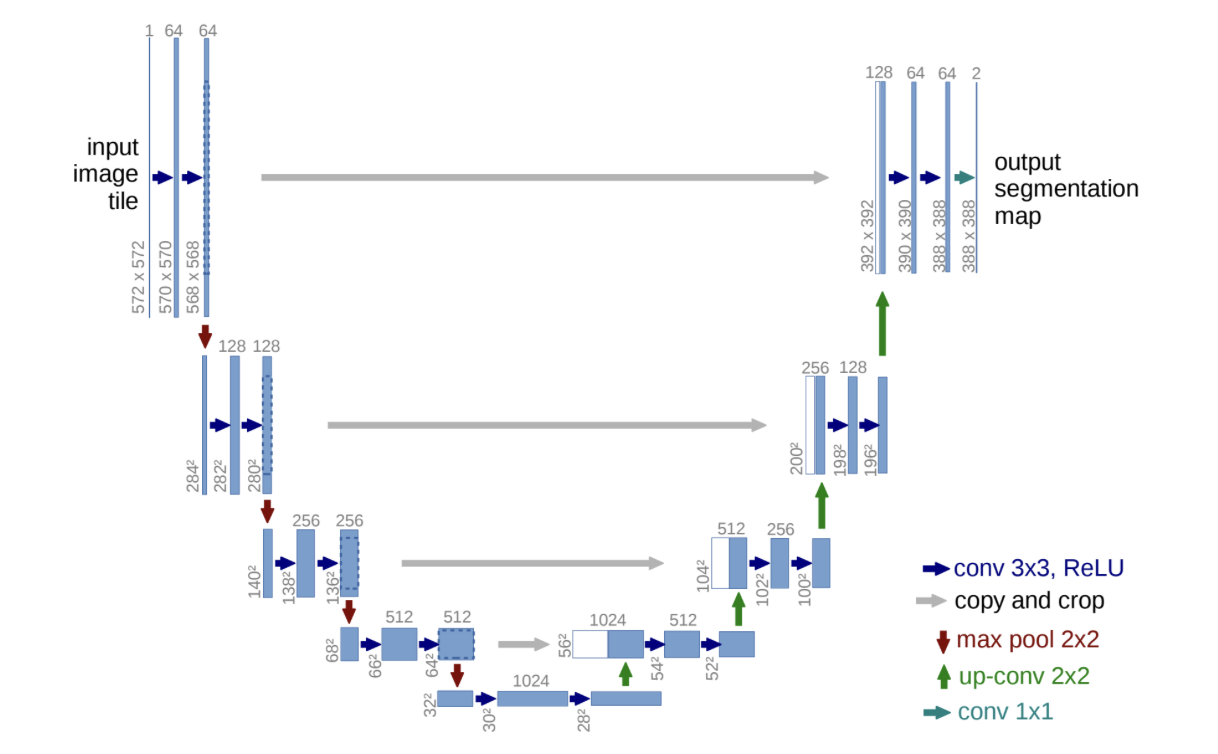

In [18]:
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(
                in_channels=in_channels,
                out_channels=out_channels,
                kernel_size=3,
                padding=1
            ),
            nn.GroupNorm(8, out_channels),
            nn.ReLU(),
            nn.Conv2d(
                in_channels=out_channels,
                out_channels=out_channels,
                kernel_size=3,
                padding=1
            ),
            nn.GroupNorm(8, out_channels),
            nn.ReLU()
        )

    def forward(self, x):
        return self.layers(x)

In [19]:
class Encoder(nn.Module):
    def __init__(self, in_channels=3, channels=(32, 64, 128, 256)):
        super().__init__()

        self.blocks = nn.ModuleList()

        for i, out_channels in enumerate(channels):
            input_channels = in_channels if i == 0 else channels[i - 1]
            self.blocks.append(ConvBlock(input_channels, out_channels))

    def forward(self, x):
        activations = []

        for i, block in enumerate(self.blocks):
            x = block(x)
            activations.append(x)

            if i != len(self.blocks) - 1:
                x = F.max_pool2d(x, kernel_size=2)

        return activations

In [20]:
class DecoderBlock(nn.Module):
    def __init__(self, in_channels, skip_channels, out_channels):
        super().__init__()

        self.upconv = nn.Sequential(
            nn.Conv2d(
                in_channels=in_channels,
                out_channels=out_channels,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU()
        )

        self.conv = ConvBlock(
            in_channels=(out_channels + skip_channels),
            out_channels=out_channels
        )

    def forward(self, down, skip):
        x = F.interpolate(
            down,
            size=skip.shape[-2:],
            mode='bilinear',
            align_corners=False
        )

        x = self.upconv(x)
        x = torch.cat([x, skip], dim=1)

        return self.conv(x)

In [21]:
class Decoder(nn.Module):
    def __init__(self, channels=(32, 64, 128, 256)):
        super().__init__()

        self.blocks = nn.ModuleList()

        for i in range(len(channels) - 1, 0, -1):
            self.blocks.append(
                DecoderBlock(
                    in_channels=channels[i],
                    skip_channels=channels[i - 1],
                    out_channels=channels[i - 1]
                )
            )

    def forward(self, activations):
        x = activations[-1]

        for block, skip in zip(self.blocks, reversed(activations[:-1])):
            x = block(x, skip)

        return x

In [22]:
class UNet(nn.Module):
    def __init__(self, in_channels=3, num_classes=1):
        super().__init__()

        channels = (32, 64, 128, 256)

        self.encoder = Encoder(
            in_channels=in_channels,
            channels=channels
        )

        self.decoder = Decoder(
            channels=channels
        )

        self.final = nn.Conv2d(
            in_channels=channels[0],
            out_channels=num_classes,
            kernel_size=1
        )

    def forward(self, x):
        activations = self.encoder(x)
        x = self.decoder(activations)
        return self.final(x)

## V. U-Net Training

In [23]:
sys.path.insert(0, str(DATA_DIR))
from submission import encode_rle, score_val

set_seed(SEED)
unet = UNet().to(DEVICE)
bce_criterion = nn.BCEWithLogitsLoss(reduction='none', pos_weight=torch.tensor([3.0], device=DEVICE))
dice_criterion = DiceLoss()
optimizer = torch.optim.AdamW(unet.parameters(), lr=3e-4, weight_decay=0.001)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=3, min_lr=1e-6)

EPOCHS = 40

In [24]:
def compute_loss(logits, masks):
    logits = logits.squeeze(1)

    valid = masks != 255
    targets = (masks == 1).float()

    if not valid.any():
        return logits.sum() * 0

    bce = bce_criterion(logits, targets)[valid].mean()
    dice = dice_criterion(logits, masks)

    return bce + dice

In [25]:
def train_unet(
    model,
    train_loader,
    val_loader,
    optimizer,
    scheduler,
    epochs=EPOCHS
):
    history = {
        'train_loss': [],
        'train_miou': [],
        'train_metrics': [],
        'val_loss': [],
        'val_miou': [],
        'val_metrics': [],
        'lr': []
    }

    best_miou = -float('inf')

    for epoch in range(epochs):

        model.train()

        train_total_loss = 0.
        train_total_pixels = 0
        train_cm = np.zeros((2, 2), dtype=np.int64)

        for images, masks in train_loader:
            images, masks = images.to(DEVICE), masks.to(DEVICE)

            optimizer.zero_grad()
            logits = model(images)
            loss = compute_loss(logits, masks)
            loss.backward()
            optimizer.step()

            valid = masks != 255
            n_valid = valid.sum().item()

            train_total_loss += loss.item() * n_valid
            train_total_pixels += n_valid

            with torch.no_grad():
                predictions = (logits.squeeze(1) >= 0.0).long()
                target = masks[valid].cpu().numpy()
                pred = predictions[valid].cpu().numpy()

                train_cm += np.bincount(
                    2 * target + pred, minlength=4
                ).reshape(2, 2)

        train_loss = train_total_loss / train_total_pixels
        history['train_loss'].append(train_loss)

        intersection = np.diag(train_cm)
        union = train_cm.sum(0) + train_cm.sum(1) - intersection

        iou = np.divide(
            intersection,
            union,
            out=np.full(2, np.nan),
            where=union > 0
        )

        train_miou = float(iou[union > 0].mean())
        history['train_miou'].append(train_miou)

        train_metrics = calculate_metrics(train_cm)
        history['train_metrics'].append(train_metrics)

        model.eval()

        val_total_loss = 0.
        val_total_pixels = 0
        val_cm = np.zeros((2, 2), dtype=np.int64)

        with torch.no_grad():
            with open('val_predictions.csv', 'w', newline='', encoding='utf-8') as f:
                writer = csv.writer(f)
                writer.writerow(['id', 'rle'])
                index = 0

                for images, masks in val_loader:
                    images, masks = images.to(DEVICE), masks.to(DEVICE)

                    logits = model(images)
                    loss = compute_loss(logits, masks)

                    valid = masks != 255
                    n_valid = valid.sum().item()

                    val_total_loss += loss.item() * n_valid
                    val_total_pixels += n_valid

                    predictions = (
                        (logits.squeeze(1) >= 0.0)
                        .to(torch.uint8).cpu().numpy()
                    )
                    masks_np = masks.cpu().numpy()

                    for prediction, mask in zip(predictions, masks_np):
                        name = val_loader.dataset.names[index]
                        writer.writerow([name, encode_rle(prediction)])
                        index += 1

                        image_valid = mask != 255

                        val_cm += np.bincount(
                            2 * mask[image_valid] + prediction[image_valid],
                            minlength=4
                        ).reshape(2, 2)

        val_loss = val_total_loss / val_total_pixels
        history['val_loss'].append(val_loss)

        val_metrics = calculate_metrics(val_cm)

        history['val_metrics'].append(val_metrics)

        official_metrics = score_val(
            'val_predictions.csv', data_dir=DATA_DIR
        )
        val_miou = official_metrics['miou']
        history['val_miou'].append(val_miou)

        scheduler.step(val_miou)
        current_lr = optimizer.param_groups[0]['lr']
        history['lr'].append(current_lr)

        if val_miou > best_miou:
            best_miou = val_miou
            torch.save(model.state_dict(), 'best_unet.pth')

        print(
            f'Epoch {epoch + 1:02d}/{epochs} | '
            f'Train Loss: {train_loss:.4f} | '
            f'Train mIoU: {train_miou:.4f} | '
            f'Val Loss: {val_loss:.4f} | '
            f'Val mIoU: {val_miou:.4f} | '
            f'LR: {current_lr:.2e}'
        )

    model.load_state_dict(
        torch.load('best_unet.pth', map_location=DEVICE, weights_only=True)
    )
    return history

In [26]:
history = train_unet(
    model=unet,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer,
    scheduler=scheduler,
    epochs=EPOCHS
)

Epoch 01/40 | Train Loss: 1.1713 | Train mIoU: 0.6012 | Val Loss: 1.0093 | Val mIoU: 0.6121 | LR: 3.00e-04
Epoch 02/40 | Train Loss: 0.9535 | Train mIoU: 0.6709 | Val Loss: 0.8690 | Val mIoU: 0.6392 | LR: 3.00e-04
Epoch 03/40 | Train Loss: 0.8591 | Train mIoU: 0.6864 | Val Loss: 0.8268 | Val mIoU: 0.6321 | LR: 3.00e-04
Epoch 04/40 | Train Loss: 0.7678 | Train mIoU: 0.7186 | Val Loss: 0.7095 | Val mIoU: 0.6919 | LR: 3.00e-04
Epoch 05/40 | Train Loss: 0.6957 | Train mIoU: 0.7435 | Val Loss: 0.6408 | Val mIoU: 0.7538 | LR: 3.00e-04
Epoch 06/40 | Train Loss: 0.6449 | Train mIoU: 0.7638 | Val Loss: 0.6703 | Val mIoU: 0.6885 | LR: 3.00e-04
Epoch 07/40 | Train Loss: 0.6280 | Train mIoU: 0.7698 | Val Loss: 0.6231 | Val mIoU: 0.7189 | LR: 3.00e-04
Epoch 08/40 | Train Loss: 0.6063 | Train mIoU: 0.7758 | Val Loss: 0.5558 | Val mIoU: 0.7912 | LR: 3.00e-04
Epoch 09/40 | Train Loss: 0.5932 | Train mIoU: 0.7789 | Val Loss: 0.5709 | Val mIoU: 0.7547 | LR: 3.00e-04
Epoch 10/40 | Train Loss: 0.5635 | Tr

## VI. Results & Visualization

### i. Training curves

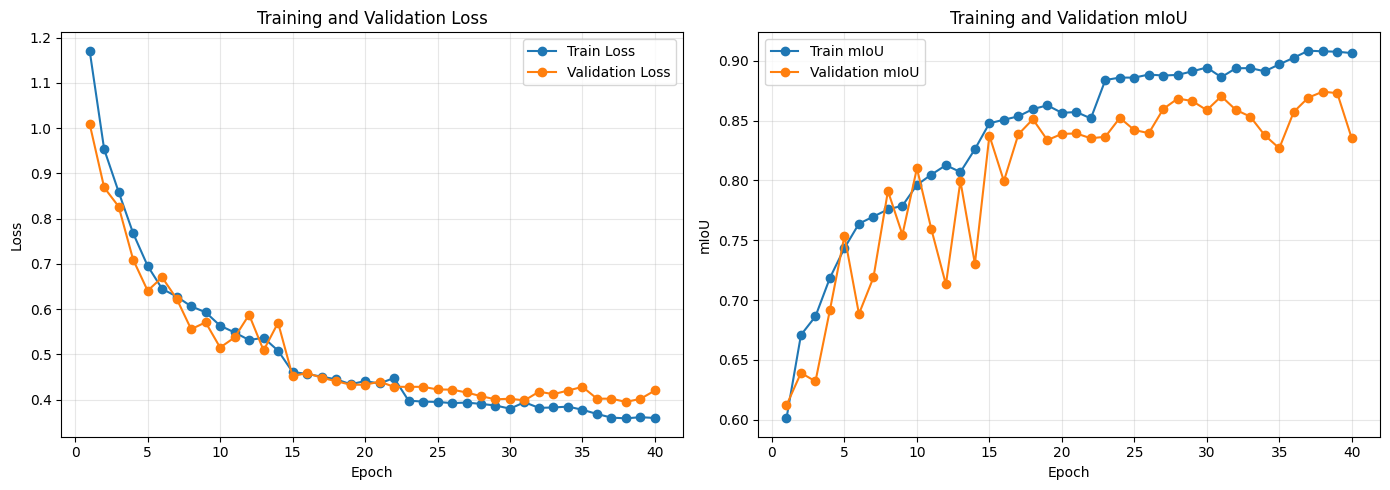

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

epochs = range(1, len(history['train_loss']) + 1)

axes[0].plot(epochs, history['train_loss'], marker='o', label='Train Loss')
axes[0].plot(epochs, history['val_loss'], marker='o', label='Validation Loss')
axes[0].set_title('Training and Validation Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epochs, history['train_miou'], marker='o', label='Train mIoU')
axes[1].plot(epochs, history['val_miou'], marker='o', label='Validation mIoU')
axes[1].set_title('Training and Validation mIoU')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('mIoU')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### ii. Evaluation Metrics

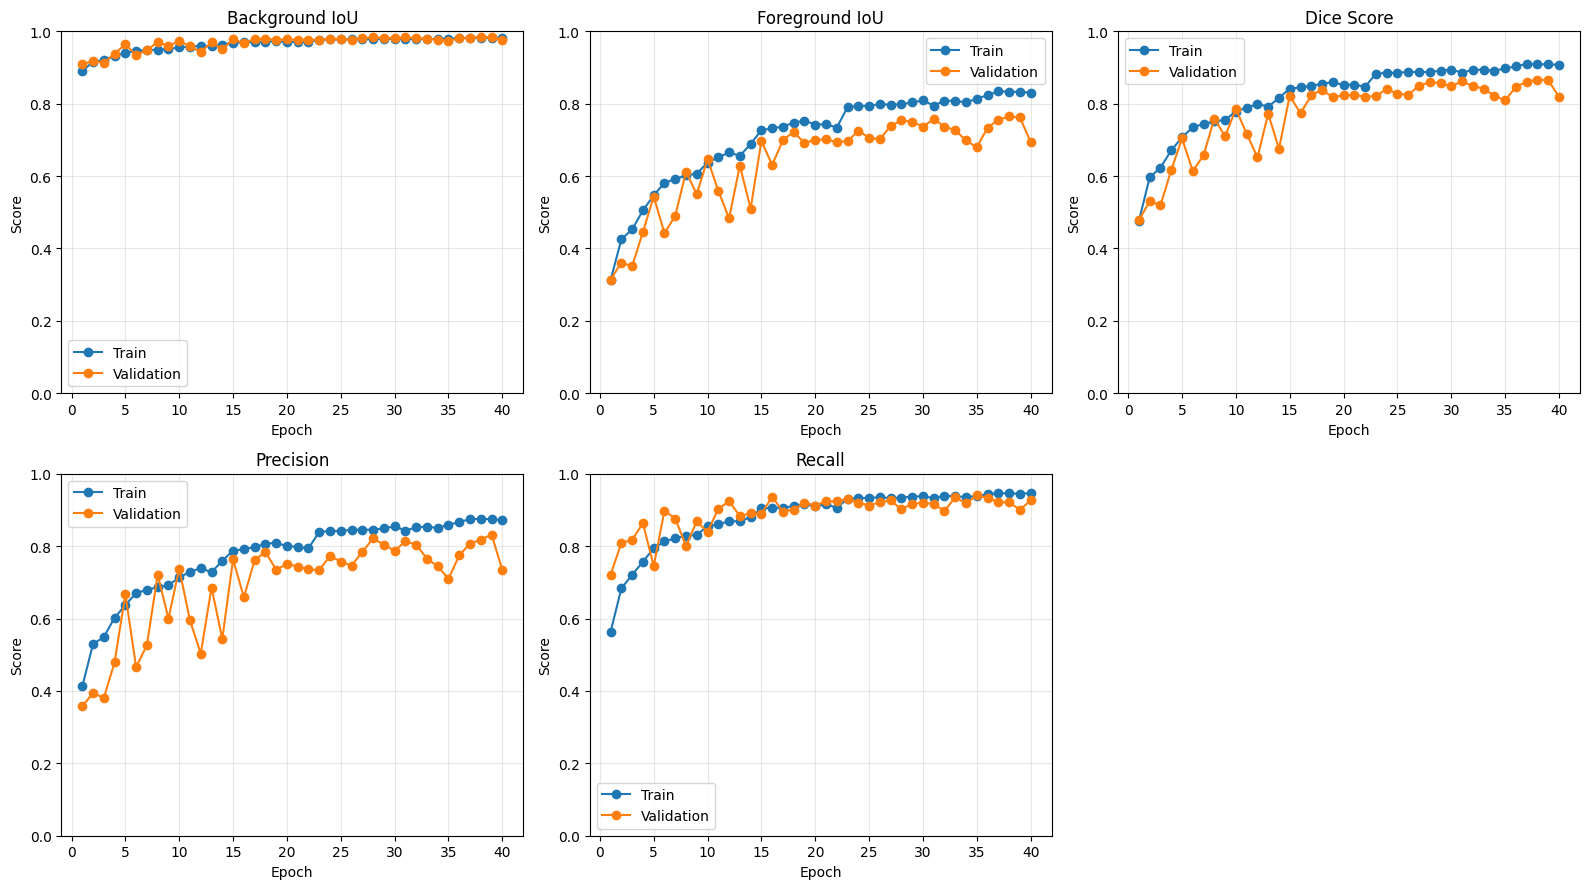

In [28]:
metric_names = {
    'bg_iou': 'Background IoU',
    'fg_iou': 'Foreground IoU',
    'dice': 'Dice Score',
    'precision': 'Precision',
    'recall': 'Recall'
}

epochs = np.arange(1, len(history['train_metrics']) + 1)

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for ax, (key, title) in zip(axes, metric_names.items()):

    train_values = [metrics[key] for metrics in history['train_metrics']]
    val_values = [metrics[key] for metrics in history['val_metrics']]

    ax.plot(epochs, train_values, marker='o', label='Train')
    ax.plot(epochs, val_values, marker='o', label='Validation')

    ax.set_title(title)
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Score')
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.3)
    ax.legend()

fig.delaxes(axes[-1])
plt.tight_layout()
plt.show()

In [29]:
best_epoch = int(np.argmax(history['val_miou']))
best_boundary_f1 = evaluate_boundary_f1(unet, val_loader)

results = pd.DataFrame({
    'Metric': list(metric_names.values()) + ['Boundary F1'],
    'Train': [
        history['train_metrics'][best_epoch][key]
        for key in metric_names
    ] + [np.nan],
    'Validation': [
        history['val_metrics'][best_epoch][key]
        for key in metric_names
    ] + [best_boundary_f1]
})

display(results.round(4))

,Metric,Train,Validation
0,Background IoU,0.9825,0.9836
1,Foreground IoU,0.8333,0.7647
2,Dice Score,0.9091,0.8666
3,Precision,0.8750,0.8181
4,Recall,0.9458,0.9214
5,Boundary F1,NaN,0.4708


### iii. Prediction & Probability Map

In [30]:
def visualize_predictions(model, dataset, indices, threshold=0.5):
    model.eval()

    fig, axes = plt.subplots(len(indices), 4, figsize=(16, 4 * len(indices)))

    with torch.no_grad():
        for row, i in enumerate(indices):
            image, mask = dataset[i]

            logits = model(image.unsqueeze(0).to(DEVICE))
            probabilities = torch.sigmoid(logits[0, 0]).cpu().numpy()
            prediction = probabilities >= threshold

            original = image.permute(1, 2, 0).numpy()
            true_mask = mask.numpy()

            axes[row, 0].imshow(original)
            axes[row, 0].set_title('Original Image')

            axes[row, 1].imshow(true_mask == 1, cmap='gray', vmin=0, vmax=1)
            axes[row, 1].set_title('True Mask')

            im = axes[row, 2].imshow(probabilities, cmap="viridis", vmin=0, vmax=1)
            axes[row, 2].set_title('Probability Map')

            axes[row, 3].imshow(prediction, cmap='gray', vmin=0, vmax=1)
            axes[row, 3].set_title('Prediction')

            for ax in axes[row]:
                ax.axis('off')

    plt.show()

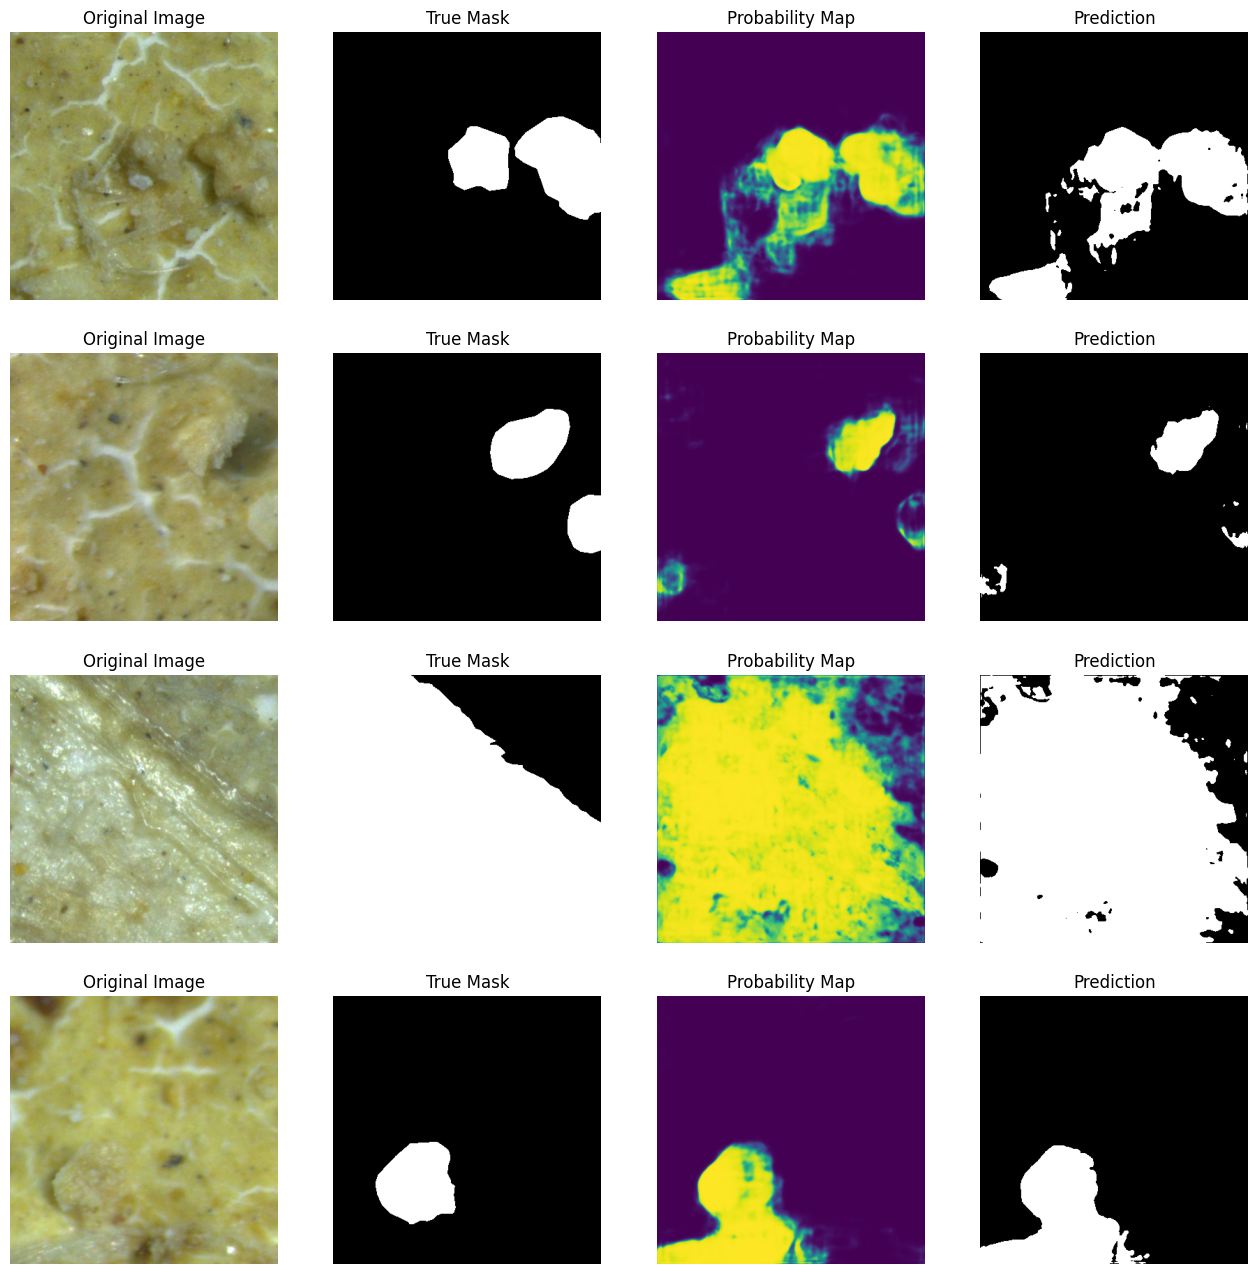

In [31]:
visualize_predictions(
    model=unet,
    dataset=val_dataset,
    indices=[1, 15, 30, 45],
    threshold=0.5
)

## VII. Postprocessing

In [45]:
set_seed(SEED)

history = train_unet(
    model=unet,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer,
    scheduler=scheduler,
    epochs=10
)

Epoch 01/10 | Train Loss: 0.3570 | Train mIoU: 0.9089 | Val Loss: 0.3981 | Val mIoU: 0.8653 | LR: 3.75e-05
Epoch 02/10 | Train Loss: 0.3560 | Train mIoU: 0.9102 | Val Loss: 0.4064 | Val mIoU: 0.8555 | LR: 1.87e-05
Epoch 03/10 | Train Loss: 0.3532 | Train mIoU: 0.9117 | Val Loss: 0.4000 | Val mIoU: 0.8694 | LR: 1.87e-05
Epoch 04/10 | Train Loss: 0.3508 | Train mIoU: 0.9131 | Val Loss: 0.3965 | Val mIoU: 0.8769 | LR: 1.87e-05
Epoch 05/10 | Train Loss: 0.3531 | Train mIoU: 0.9114 | Val Loss: 0.4010 | Val mIoU: 0.8662 | LR: 1.87e-05
Epoch 06/10 | Train Loss: 0.3492 | Train mIoU: 0.9134 | Val Loss: 0.3988 | Val mIoU: 0.8666 | LR: 1.87e-05
Epoch 07/10 | Train Loss: 0.3528 | Train mIoU: 0.9125 | Val Loss: 0.3952 | Val mIoU: 0.8708 | LR: 1.87e-05
Epoch 08/10 | Train Loss: 0.3487 | Train mIoU: 0.9133 | Val Loss: 0.4014 | Val mIoU: 0.8690 | LR: 9.37e-06
Epoch 09/10 | Train Loss: 0.3472 | Train mIoU: 0.9164 | Val Loss: 0.3917 | Val mIoU: 0.8748 | LR: 9.37e-06
Epoch 10/10 | Train Loss: 0.3449 | Tr

In [46]:
def postprocess_mask(
    probabilities,
    threshold=0.5,
    sigma=1.5,
    closing_iterations=1,
    min_area=30
):

    smoothed = ndimage.gaussian_filter(probabilities, sigma=sigma)
    mask = smoothed >= threshold

    if closing_iterations > 0:
        mask = ndimage.binary_closing(
            mask,
            iterations=closing_iterations,
            border_value=0
        )

    mask = ndimage.binary_fill_holes(mask)

    if min_area > 0:
        labels, num_labels = ndimage.label(mask)
        sizes = np.bincount(labels.ravel())

        keep = sizes >= min_area
        keep[0] = False

        mask = keep[labels]

    return mask.astype(np.uint8)

In [47]:
def visualize_postprocessing(
    model,
    dataset,
    indices,
    threshold=0.5,
    sigma=1.5,
    closing_iterations=1,
    min_area=30
):
    model.eval()

    fig, axes = plt.subplots(len(indices), 4, figsize=(16, 4 * len(indices)), squeeze=False)

    with torch.inference_mode():
        for row, i in enumerate(indices):
            image, mask = dataset[i]
            logits = model(image.unsqueeze(0).to(DEVICE))

            probabilities = torch.sigmoid(logits[0, 0]).cpu().numpy()
            original_prediction = (probabilities >= threshold).astype(np.uint8)

            processed_prediction = postprocess_mask(
                probabilities,
                threshold=threshold,
                sigma=sigma,
                closing_iterations=closing_iterations,
                min_area=min_area
            )

            original = image.permute(1, 2, 0).numpy()
            true_mask = mask.numpy()

            images = [
                original,
                true_mask == 1,
                original_prediction,
                processed_prediction
            ]

            titles = [
                'Original Image',
                'True Mask',
                'Original Prediction',
                'Postprocessed Prediction'
            ]

            for col, (img, title) in enumerate(zip(images, titles)):
                ax = axes[row, col]

                if col == 0:
                    ax.imshow(img)
                else:
                    ax.imshow(img, cmap='gray', vmin=0, vmax=1)

                ax.set_title(title)
                ax.axis('off')

    plt.tight_layout()
    plt.show()

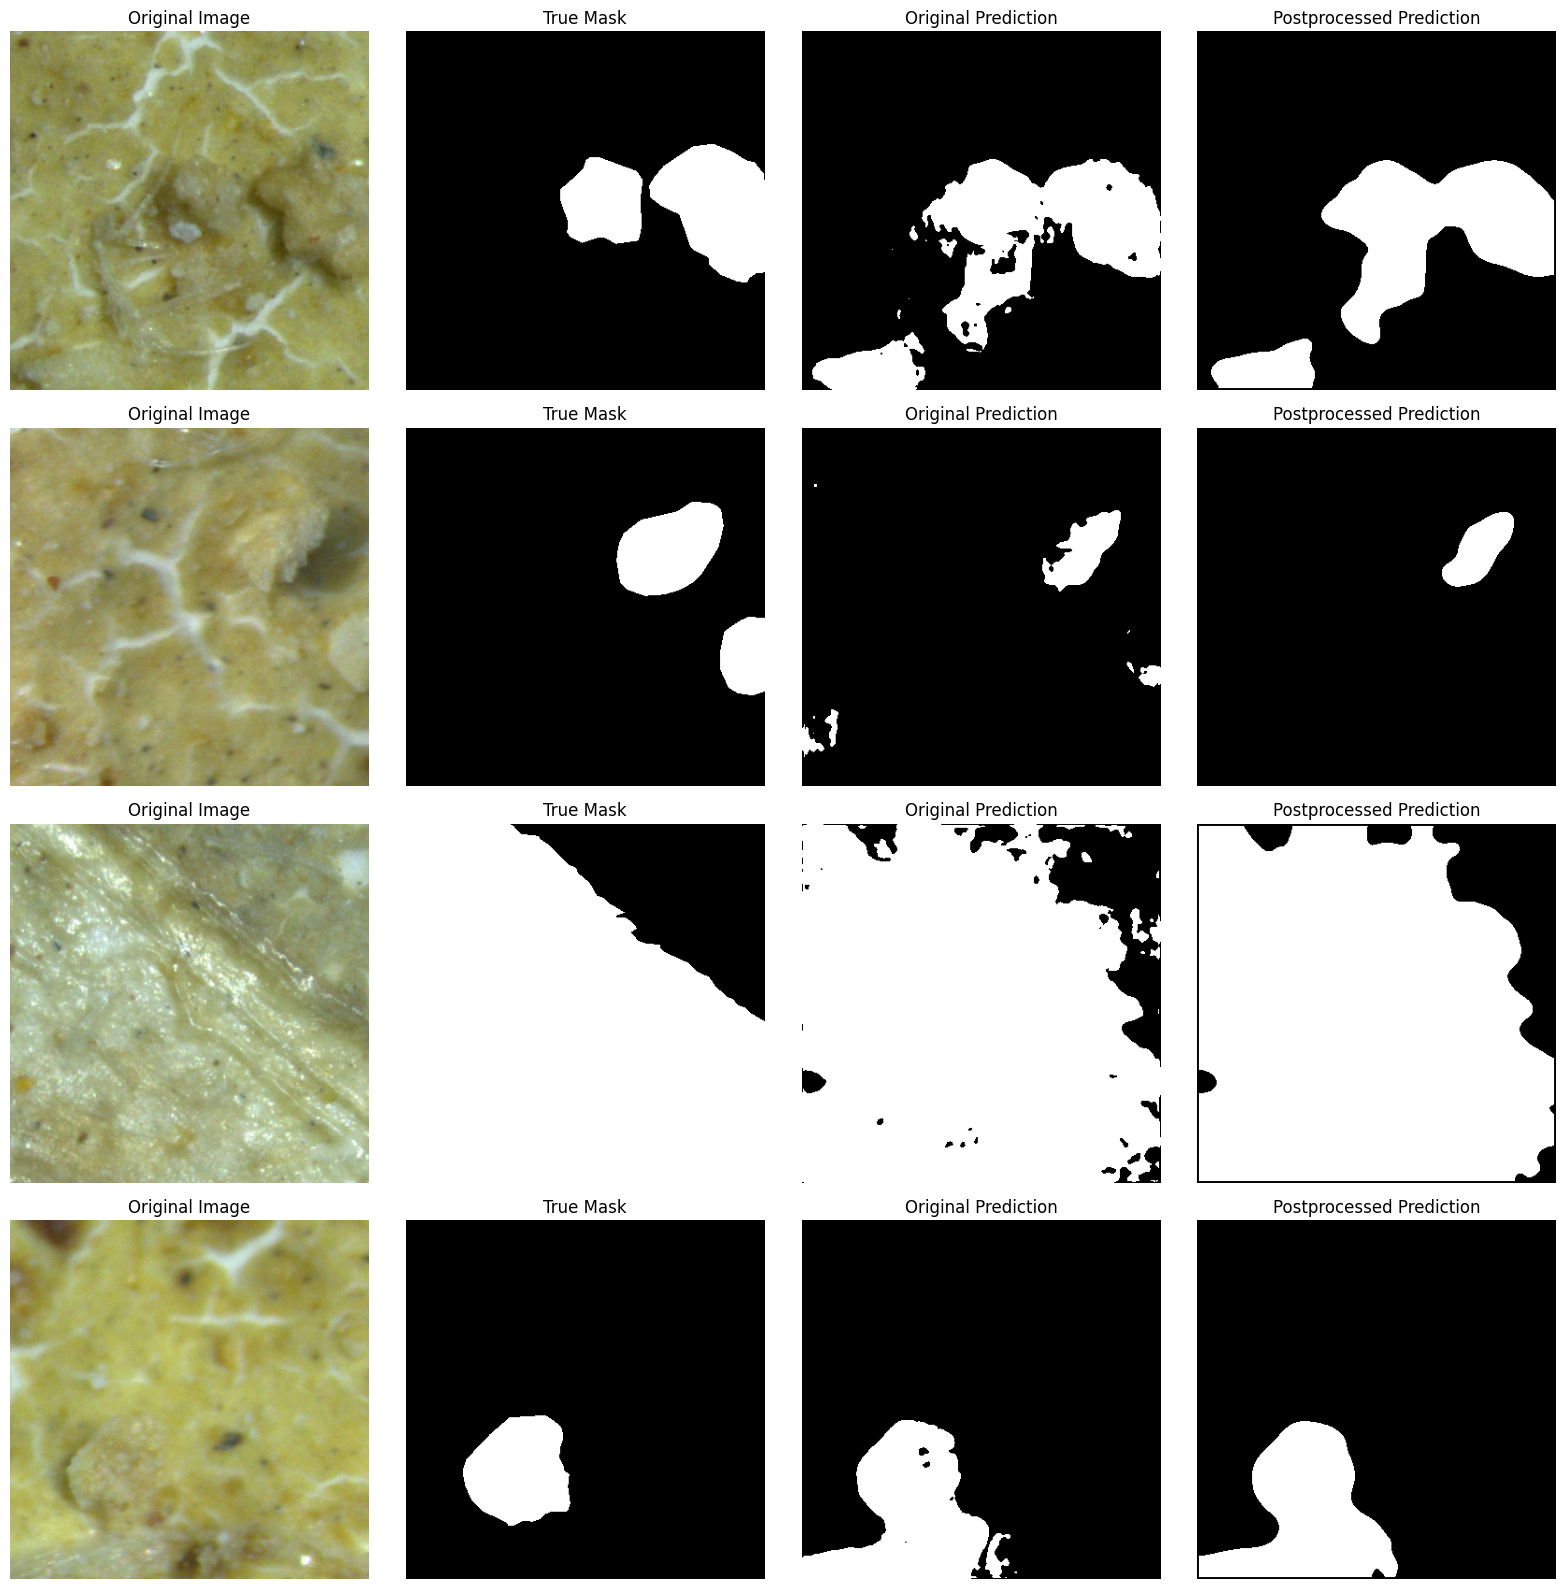

In [48]:
visualize_postprocessing(
    model=unet,
    dataset=val_dataset,
    indices=[1, 15, 30, 45],
    threshold=0.5,
    sigma=7.0,
    closing_iterations=2,
    min_area=300
)

In [49]:
@torch.inference_mode()
def predict_postprocessed(
    model,
    loader,
    threshold=0.5,
    sigma=2.0,
    closing_iterations=2,
    min_area=100
):
    model.eval()
    predictions = {}

    index = 0

    for images, _ in loader:
        images = images.to(DEVICE)

        logits = model(images)
        probabilities = torch.sigmoid(logits).cpu().numpy()

        for probability in probabilities[:, 0]:
            mask = postprocess_mask(
                probability,
                threshold=threshold,
                sigma=sigma,
                closing_iterations=closing_iterations,
                min_area=min_area
            )

            name = loader.dataset.names[index]
            predictions[name] = mask
            index += 1

    return predictions

In [50]:
val_predictions = predict_postprocessed(
    model=unet,
    loader=val_loader,
    threshold=0.5,
    sigma=7.0,
    closing_iterations=2,
    min_area=300
)

In [51]:
with open('val_postprocessed.csv', 'w', newline='', encoding='utf-8') as f:
    writer = csv.writer(f)
    writer.writerow(['id', 'rle'])

    for name, mask in val_predictions.items():
        writer.writerow([name, encode_rle(mask)])

postprocessed_metrics = score_val(
    'val_postprocessed.csv',
    data_dir=DATA_DIR
)

print('Postprocessed Val mIoU:', postprocessed_metrics['miou'])

Postprocessed Val mIoU: 0.8845613843885167


## VIII. Test-Time Augmentation

In [52]:
@torch.inference_mode()
def predict_tta(model, images):
    model.eval()

    probabilities = []

    for k in range(4):
        for flip in [False, True]:

            augmented = torch.rot90(images, k, dims=(-2, -1))

            if flip:
                augmented = torch.flip(augmented, dims=(-1,))

            logits = model(augmented)
            prediction = torch.sigmoid(logits)

            if flip:
                prediction = torch.flip(prediction, dims=(-1,))

            prediction = torch.rot90(prediction, -k, dims=(-2, -1))
            probabilities.append(prediction)

    return torch.stack(probabilities).mean(dim=0)

In [53]:
@torch.inference_mode()
def predict_tta_dataset(model, loader, threshold=0.5):
    model.eval()
    predictions = {}

    index = 0

    for images, _ in loader:
        images = images.to(DEVICE)

        probabilities = predict_tta(model, images)
        probabilities = probabilities[:, 0].cpu().numpy()

        for probability in probabilities:
            prediction = postprocess_mask(
                probability,
                threshold=threshold,
                sigma=7.0,
                closing_iterations=2,
                min_area=300
            )

            name = loader.dataset.names[index]
            predictions[name] = prediction
            index += 1

    return predictions

In [54]:
val_tta_predictions = predict_tta_dataset(
    model=unet,
    loader=val_loader,
    threshold=0.5
)

In [55]:
with open('val_tta.csv', 'w', newline='', encoding='utf-8') as f:
    writer = csv.writer(f)
    writer.writerow(['id', 'rle'])

    for name, mask in val_tta_predictions.items():
        writer.writerow([name, encode_rle(mask)])

tta_metrics = score_val(
    'val_tta.csv',
    data_dir=DATA_DIR
)

print('Original Val mIoU:', max(history['val_miou']))
print('Postprocessed Val mIoU:', postprocessed_metrics['miou'])
print('TTA Val mIoU:', tta_metrics['miou'])

Original Val mIoU: 0.8782410356930146
Postprocessed Val mIoU: 0.8845613843885167
TTA Val mIoU: 0.8859662201182733


## IX. Submission

In [56]:
class TestDataset(Dataset):
    def __init__(self):
        self.names = sorted(p.stem for p in (DATA_DIR / 'test' / 'images').glob('*.jpg'))

    def __len__(self):
        return len(self.names)

    def __getitem__(self, idx):
        name = self.names[idx]

        image = load_image(DATA_DIR / 'test' / 'images' / f'{name}.jpg')
        image = torch.from_numpy(np.ascontiguousarray(image.transpose(2, 0, 1))).float()

        return image, name


test_dataset = TestDataset()

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

In [57]:
@torch.inference_mode()
def predict_test(model, loader, threshold=0.5):
    model.eval()

    predictions = {}

    for images, names in loader:
        images = images.to(DEVICE)

        logits = model(images)
        probabilities = torch.sigmoid(logits)

        masks = (probabilities[:, 0] >= threshold).to(torch.uint8).cpu().numpy()

        for name, mask in zip(names, masks):
            predictions[name] = mask

    return predictions

In [58]:
from submission import read_predictions

unet.eval()
test_predictions = {}

with torch.inference_mode():
    for images, names in test_loader:
        images = images.to(DEVICE)

        probabilities = predict_tta(unet, images)[:, 0].cpu().numpy()

        for name, probability in zip(names, probabilities):
            mask = postprocess_mask(
                probability,
                threshold=0.5,
                sigma=7.0,
                closing_iterations=2,
                min_area=300
            )

            test_predictions[name] = mask

with open('submission.csv', 'w', newline='', encoding='utf-8') as f:
    writer = csv.writer(f)
    writer.writerow(['id', 'rle'])

    for name, mask in test_predictions.items():
        writer.writerow([name, encode_rle(mask)])

checked = read_predictions(
    'submission.csv',
    split='test',
    data_dir=DATA_DIR
)